# Despesas de viagem do BNDES (2009–2026): quem viaja, quem gasta e o efeito da pandemia

**Autoras:** Giovanna Poggi e Juliana Neto
**Instituição:** Centro Universitário La Salle do Rio de Janeiro (UniLaSalle-RJ)  
**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) · 6º período · Bacharelado em Sistemas de Informação · 2026.2
**Professor orientador:** Alexandre Neves Louzada

Este notebook é a exploração que sustenta o artigo em `docs/index.html`. Ele lê a base tratada por `src/etl.py`, responde às perguntas de pesquisa e exporta as figuras do artigo para `docs/assets/`.

**Perguntas de pesquisa**
- **RQ1.** Quais grupos de empregados (profissão, cargo e área) mais viajam?
- **RQ2.** Quais grupos concentram o maior gasto com viagens?
- **RQ3.** Como a pandemia de COVID-19 (mar/2020 a dez/2021) alterou o volume, os motivos e o custo das viagens?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src import etl

ASSETS = RAIZ / "docs" / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)

# padrão visual único: azul = cor principal, laranja = destaque, cinza = referência
AZUL, AZUL_CLARO, LARANJA, CINZA = "#1e3a8a", "#3b82f6", "#ea580c", "#9ca3af"
sns.set_theme(style="ticks", font_scale=1.0)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 200,
                     "savefig.bbox": "tight"})

def salvar(fig, nome):
    fig.savefig(ASSETS / nome)

# rótulos com acento para exibir os motivos normalizados (a chave fica sem acento na base)
ROTULO_MOTIVO = {
    "ACOMPANHAMENTO DE PROJETO": "Acompanhamento de projeto",
    "REUNIAO EM ORGAOS GOVERNAMENTAIS": "Reunião em órgãos governamentais",
    "PARTICIPACAO EM CONGRESSOS, FEIRAS E SEMINARIOS": "Congressos, feiras e seminários",
    "FOMENTO": "Fomento",
    "OUTROS": "Outros",
    "ANALISE DE PROJETO": "Análise de projeto",
    "TREINAMENTO NACIONAL": "Treinamento nacional",
    "REUNIAO NOS ESCRITORIOS REGIONAIS": "Reunião nos escritórios regionais",
    "REPRESENTACAO EM COLEGIADOS": "Representação em colegiados",
    "AVALIACAO DE BENS": "Avaliação de bens",
}
rotulo_motivo = lambda m: ROTULO_MOTIVO.get(m, m.capitalize())

reais = mticker.FuncFormatter(lambda x, _: f"R$ {x/1e6:,.0f} mi".replace(",", "."))
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Aquisição e pipeline

A ingestão fica em `src/etl.py` e roda inteira com `python -m src.etl`. Aqui o notebook só garante que a base tratada existe. Se ela não existir, o pipeline é executado: baixa as bases do portal do BNDES e o IPCA da API do Banco Central com `requests`.

O log abaixo registra cada decisão do tratamento (nada é removido sem registro).

In [2]:
caminho = etl.PROCESSED_DIR / "viagens.csv.gz"
if not caminho.exists():
    etl.executar_pipeline()

df = etl.carregar_processado(caminho)
log = pd.read_json(etl.PROCESSED_DIR / "etl_log.json", typ="series")
print(f"{len(df):,} viagens, {df['pessoa_id'].nunique():,} pessoas, de {df['data_partida'].min():%m/%Y} a {df['data_partida'].max():%m/%Y}")
log

144,930 viagens, 5,480 pessoas, de 01/2009 a 07/2026


trechos_lidos                                                                        303868
trechos_por_formato                                   {'2009-2019': 238714, '2020+': 65154}
nulos_apos_conversao                       {'valorpassagem': 1, 'datachegadadestino': 2916}
motivos_distintos                         {'bruto': 215, 'normalizado': 214, 'principal'...
trechos_com_motivo_composto                                                            3466
viagens                                                                              144930
viagens_total_divergente_entre_trechos                                                  152
viagens_valor_total_zero                                                                780
homonimos_empregados                                                                      4
cobertura_profissao                                                                    0.76
cobertura_area_organograma                                                      

### 1.1 Por que o pipeline agrega por viagem

O arquivo bruto tem uma linha por **trecho** (ida, volta, conexões). Os campos de valor total, hospedagem e locação são da viagem inteira e se repetem em cada trecho, então somar linha a linha contaria o gasto duas ou mais vezes. A checagem abaixo usa o arquivo bruto para mostrar o tamanho do erro que o pipeline evita.

In [3]:
bruto = etl.tratar_trechos(etl.ler_viagens(etl.RAW_DIR / "despesas-viagens.csv"), {})
soma_ingenua = bruto["valortotalviagemptpbndes"].sum()
soma_correta = df["valor_total"].sum()
print(f"soma por trecho (errada): R$ {soma_ingenua/1e6:,.1f} mi")
print(f"soma por viagem (correta): R$ {soma_correta/1e6:,.1f} mi  ->  a soma ingênua infla o gasto em {soma_ingenua/soma_correta - 1:.0%}")
print(f"trechos por viagem: {bruto.groupby('codigoviagem').size().describe()[['mean','50%','max']].round(2).to_dict()}")

soma por trecho (errada): R$ 638.0 mi
soma por viagem (correta): R$ 261.4 mi  ->  a soma ingênua infla o gasto em 144%
trechos por viagem: {'mean': 2.1, '50%': 2.0, 'max': 15.0}


### 1.2 Dois formatos no mesmo arquivo

Os registros de 2009–2019 e os de 2020 em diante seguem padrões diferentes de data, número e código de cargo. O pipeline marca cada viagem com `formato_registro`. A tabela mostra o efeito: até 2019, passagens + diárias + acréscimos fecham exatamente o valor total; a partir de 2020, o total passa a incluir itens que não aparecem detalhados.

In [4]:
componentes = df[["valor_passagens", "valor_diarias", "valor_acrescimos"]].sum(axis=1)
fecha = np.isclose(componentes, df["valor_total"], atol=1)
resumo_formato = df.assign(fecha=fecha).groupby("formato_registro").agg(
    viagens=("codigoviagem", "size"),
    componentes_fecham_total=("fecha", "mean"),
    internacionais=("internacional", "mean"),
    cargos_distintos=("cargo_codigo", "nunique"),
)
resumo_formato

,viagens,componentes_fecham_total,internacionais,cargos_distintos
formato_registro,,,,
2009-2019,116496,1.00,0.00,11
2020+,28434,0.32,0.03,10


In [5]:
pd.crosstab(df["cargo"], df["formato_registro"]).loc[lambda t: t.sum(axis=1).sort_values(ascending=False).index].head(12)

formato_registro,2009-2019,2020+
cargo,,
Nível Superior,58311,0
Gerente Executivo,39496,0
DAS-1011 (Assessoramento),0,14084
Assessor,6036,722
DAS-1014 (Coordenação),0,4977
Superintendente Executivo,3548,0
DAS-1013 (Coordenação),0,3530
Nível Médio,2362,376
Não se aplica,2470,0


**Consequência para a análise:** os códigos de cargo mudam por completo em 2020 (até 2019 predominam *Nível Superior* e *Gerente Executivo*; depois, códigos DAS), então o cargo é analisado **separadamente por período**. A **profissão** vem da base de empregados e é fixa por pessoa, por isso é a dimensão usada para comparar todo o período. Viagens internacionais só passam a ser registradas em 2020.

## 2. Estatística descritiva e dispersão

In [6]:
numericas = ["n_trechos", "n_diarias", "valor_passagens", "valor_diarias", "valor_hospedagem", "valor_total", "valor_total_real"]
df.groupby("formato_registro")[["n_diarias", "valor_total", "valor_total_real"]].describe().T

formato_registro        2009-2019      2020+
n_diarias        count 116,496.00  28,434.00
                 mean        2.13       2.35
                 std         1.26       1.79
                 min         0.00       0.00
                 25%         1.00       1.00
                 50%         2.00       2.00
                 75%         3.00       3.00
                 max        30.00      96.00
valor_total      count 116,496.00  28,434.00
                 mean    1,276.55   3,962.32
                 std       642.14   5,165.74
                 min         0.00       0.00
                 25%       900.04   2,132.93
                 50%     1,187.16   3,104.09
                 75%     1,564.77   4,386.80
                 max    40,694.66 154,340.69
valor_total_real count 116,496.00  28,434.00
                 mean    2,534.56   4,427.62
                 std     1,254.75   5,823.80
                 min         0.00       0.00
                 25%     1,766.57   2,429.62
                 50%     2,407.69   3,489.54
                 75%     3,151.75   4,863.21
                 max    93,481.93 193,373.37

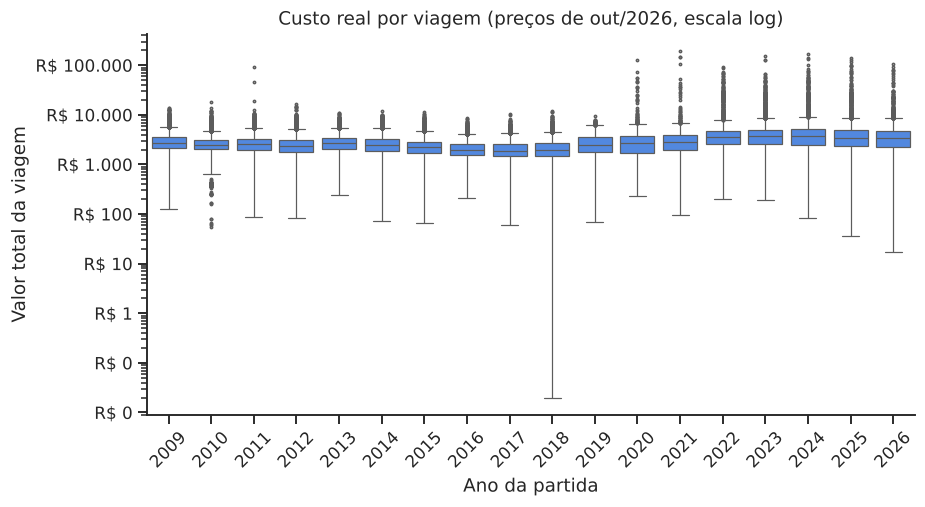

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df[df["valor_total_real"] > 0], x="ano", y="valor_total_real", color=AZUL_CLARO, fliersize=1.5, linewidth=0.8, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R$ {x:,.0f}".replace(",", ".")))
ax.set_title("Custo real por viagem (preços de out/2026, escala log)")
ax.set_xlabel("Ano da partida")
ax.set_ylabel("Valor total da viagem")
ax.tick_params(axis="x", rotation=45)
salvar(fig, "fig_custo_por_viagem.png")
plt.show()

A mediana real do custo por viagem fica entre R$ 1,9 mil e R$ 2,7 mil de 2009 a 2019 e sobe para cerca de R$ 3,5 mil a partir de 2022. A correção pelo IPCA elimina o efeito da inflação, mas o salto coincide com a mudança no formato de registro, em que o total deixa de ser a soma dos componentes detalhados (seção 1.2). Por isso a comparação de custo entre os dois períodos é feita com cautela.

Outliers foram **sinalizados, não removidos** (`outlier_valor`, regra Q3 + 1,5·IQR calculada em cada formato de registro):

In [8]:
df.groupby("formato_registro")["outlier_valor"].agg(["sum", "mean"])

,sum,mean
formato_registro,,
2009-2019,4690,0.04
2020+,1529,0.05


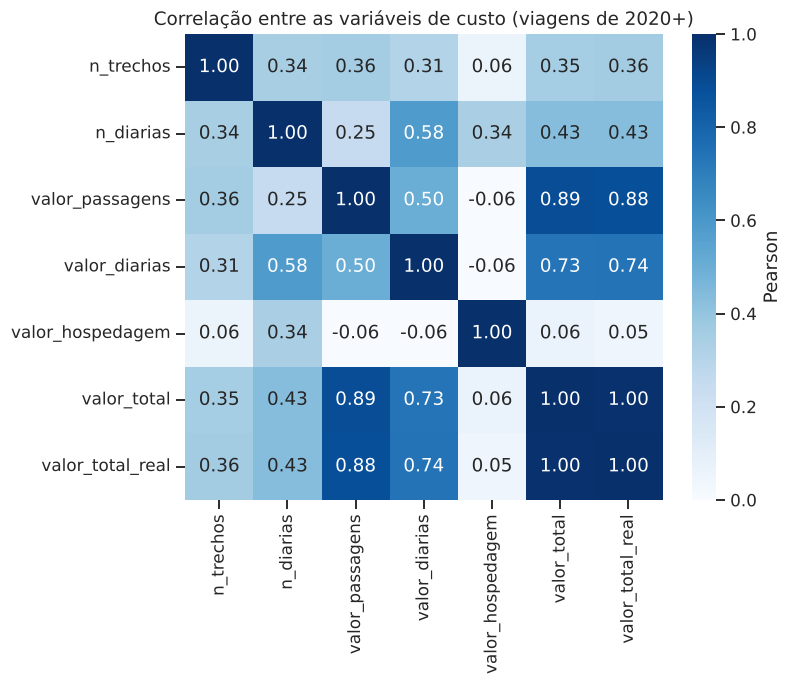

In [9]:
corr = df.loc[df["formato_registro"] == "2020+", numericas].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "Pearson"})
ax.set_title("Correlação entre as variáveis de custo (viagens de 2020+)")
salvar(fig, "fig_correlacao.png")
plt.show()

O valor total acompanha principalmente a **passagem** (r = 0,89) e, em seguida, o valor das diárias (r = 0,73); a hospedagem quase não se relaciona com o total (r = 0,06), porque vem zerada na maioria das viagens. Ou seja, o custo de uma viagem é puxado pelo deslocamento mais do que pela estadia.

Medida de concentração: quanto do gasto fica com poucas pessoas?

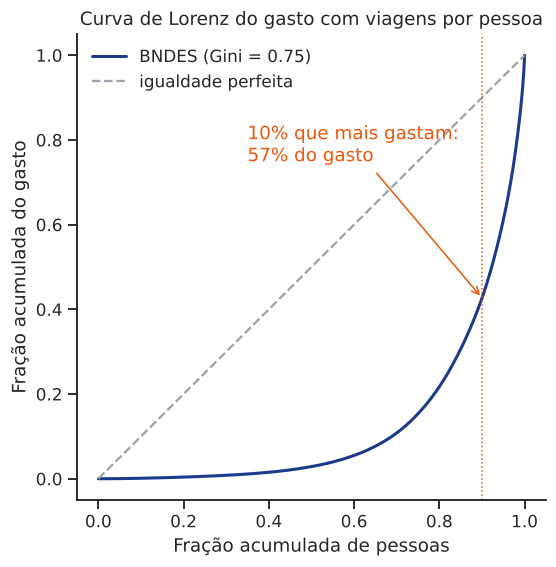

Gini = 0.747 | top 10% = 57.4% do gasto real


In [10]:
gasto_pessoa = df.groupby("pessoa_id")["valor_total_real"].sum().sort_values()
acumulado = gasto_pessoa.cumsum() / gasto_pessoa.sum()
pessoas = np.arange(1, len(gasto_pessoa) + 1) / len(gasto_pessoa)
gini = 1 - 2 * np.trapezoid(acumulado, pessoas)
top10 = gasto_pessoa.tail(int(len(gasto_pessoa) * 0.10)).sum() / gasto_pessoa.sum()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(pessoas, acumulado, color=AZUL, lw=2, label=f"BNDES (Gini = {gini:.2f})")
ax.plot([0, 1], [0, 1], color=CINZA, ls="--", label="igualdade perfeita")
ax.axvline(0.9, color=LARANJA, lw=1, ls=":")
ax.annotate(f"10% que mais gastam:\n{top10:.0%} do gasto", xy=(0.9, acumulado.iloc[int(len(acumulado)*0.9)]),
            xytext=(0.35, 0.75), arrowprops=dict(arrowstyle="->", color=LARANJA), color=LARANJA)
ax.set_title("Curva de Lorenz do gasto com viagens por pessoa")
ax.set_xlabel("Fração acumulada de pessoas")
ax.set_ylabel("Fração acumulada do gasto")
ax.legend(frameon=False, loc="upper left")
salvar(fig, "fig_lorenz.png")
plt.show()
print(f"Gini = {gini:.3f} | top 10% = {top10:.1%} do gasto real")

## 3. RQ1 e RQ2: quem viaja mais e quem gasta mais

### 3.1 Por profissão (base de empregados, todo o período)

A profissão vem do cruzamento por nome com a base atual de empregados. A cobertura cai nos anos antigos porque quem já saiu do banco não está nessa base; por isso a tabela traz também quantas pessoas de cada profissão viajaram e a média de viagens por pessoa, que não depende do tamanho do grupo.

In [11]:
cobertura = df.assign(tem=df["profissao"].notna()).groupby("ano")["tem"].mean()
print("cobertura da profissão por ano:", (cobertura * 100).round(0).astype(int).to_dict())

prof = df.dropna(subset=["profissao"]).groupby("profissao").agg(
    viagens=("codigoviagem", "size"),
    pessoas=("pessoa_id", "nunique"),
    gasto_real=("valor_total_real", "sum"),
    custo_mediano=("valor_total_real", "median"),
)
prof["viagens_por_pessoa"] = prof["viagens"] / prof["pessoas"]
prof["gasto_por_pessoa"] = prof["gasto_real"] / prof["pessoas"]
prof["pct_gasto"] = prof["gasto_real"] / prof["gasto_real"].sum() * 100
prof = prof.sort_values("viagens", ascending=False)
prof.head(12)

cobertura da profissão por ano: {2009: 59, 2010: 64, 2011: 69, 2012: 72, 2013: 76, 2014: 77, 2015: 78, 2016: 81, 2017: 82, 2018: 83, 2019: 85, 2020: 78, 2021: 66, 2022: 78, 2023: 80, 2024: 84, 2025: 86, 2026: 88}


,viagens,pessoas,gasto_real,custo_mediano,viagens_por_pessoa,gasto_por_pessoa,pct_gasto
profissao,,,,,,,
Engenheiro,28779,430,"81,446,914.42","2,481.05",66.93,"189,411.43",25.97
Economista,22971,389,"66,770,716.20","2,549.77",59.05,"171,647.09",21.29
Administrador,19471,379,"55,890,904.86","2,523.82",51.37,"147,469.41",17.82
Advogado,16420,411,"47,595,784.79","2,546.23",39.95,"115,804.83",15.18
Contador,13746,344,"37,405,725.53","2,494.22",39.96,"108,737.57",11.93
Analista de Sistemas,3791,248,"10,437,885.20","2,571.37",15.29,"42,088.25",3.33
Técnico Administrativo,1511,195,"4,375,661.33","2,709.13",7.75,"22,439.29",1.40
Arquiteto,1502,29,"4,562,380.60","2,615.16",51.79,"157,323.47",1.46
Técnico de Comunicação,1157,40,"3,694,602.12","2,752.63",28.93,"92,365.05",1.18


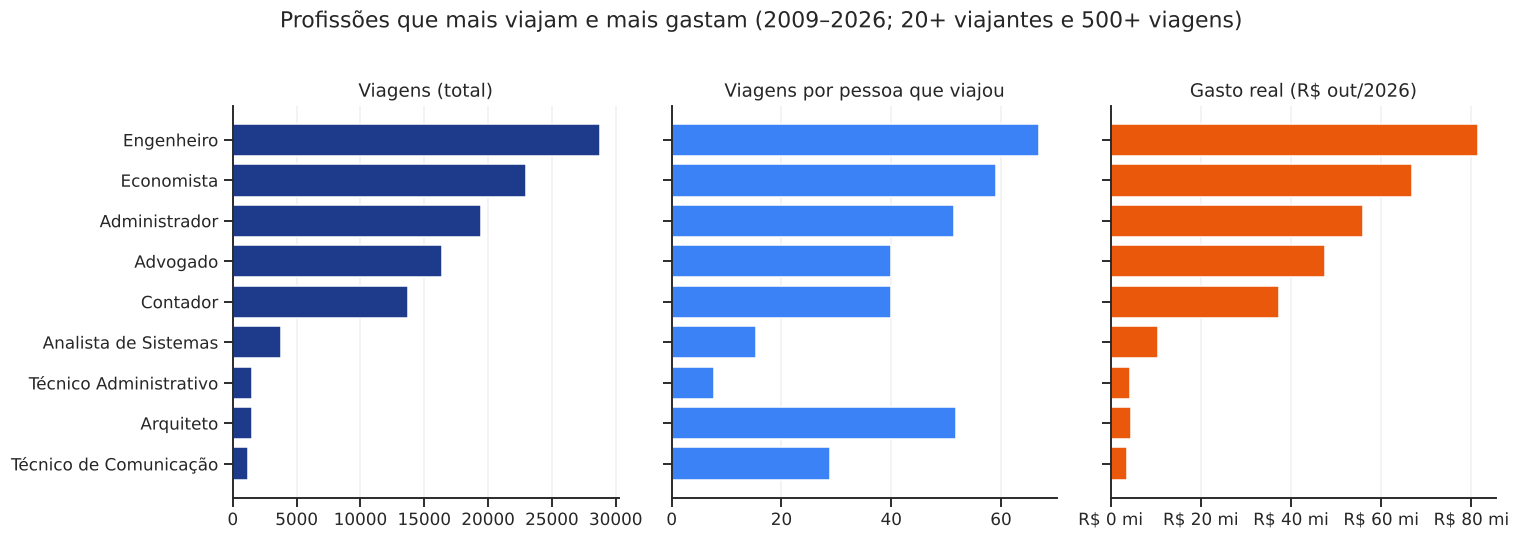

In [12]:
top = prof[(prof["pessoas"] >= 20) & (prof["viagens"] >= 500)].head(10)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)
ordem = top.index[::-1]
axes[0].barh(ordem, top.loc[ordem, "viagens"], color=AZUL)
axes[0].set_title("Viagens (total)")
axes[1].barh(ordem, top.loc[ordem, "viagens_por_pessoa"], color=AZUL_CLARO)
axes[1].set_title("Viagens por pessoa que viajou")
axes[2].barh(ordem, top.loc[ordem, "gasto_real"], color=LARANJA)
axes[2].set_title("Gasto real (R$ out/2026)")
axes[2].xaxis.set_major_formatter(reais)
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Profissões que mais viajam e mais gastam (2009–2026; 20+ viajantes e 500+ viagens)", y=1.02)
fig.tight_layout()
salvar(fig, "fig_profissao.png")
plt.show()

### 3.2 Por cargo (base de viagens, um painel por período)

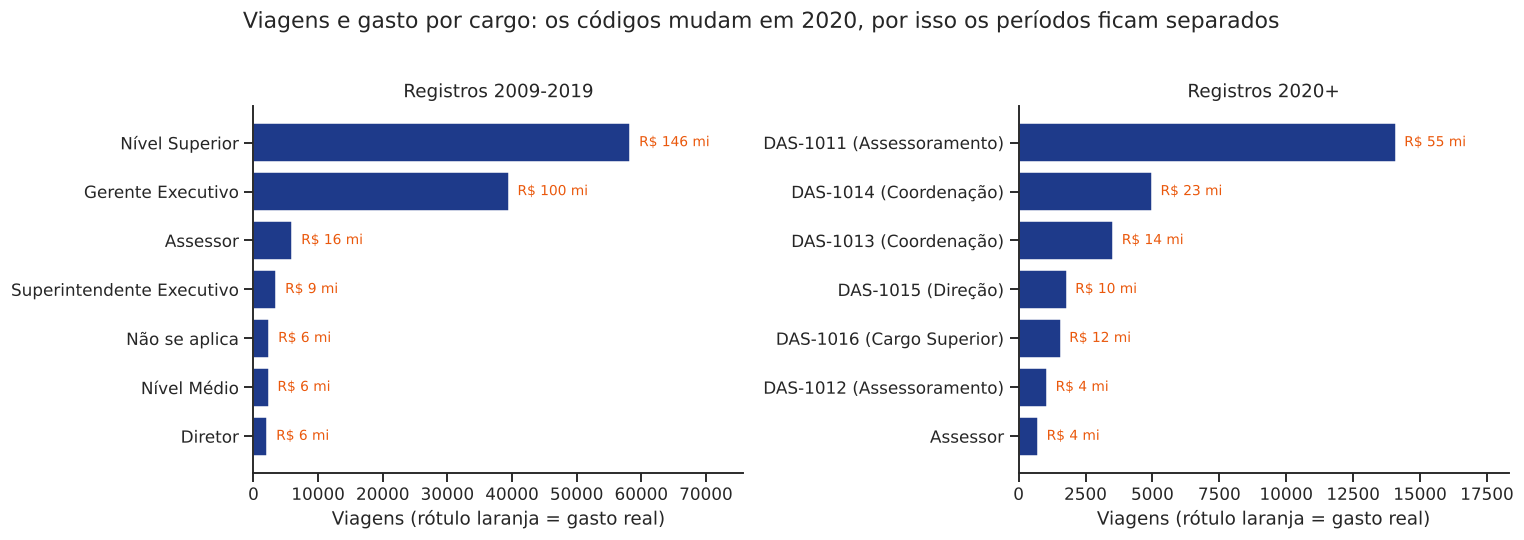

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (formato, grupo) in zip(axes, df.groupby("formato_registro")):
    c = grupo.groupby("cargo").agg(viagens=("codigoviagem", "size"), gasto_real=("valor_total_real", "sum"))
    c = c.sort_values("viagens").tail(7)
    ax.barh(c.index, c["viagens"], color=AZUL)
    for y, (v, g) in enumerate(zip(c["viagens"], c["gasto_real"])):
        ax.text(v, y, f"  R$ {g/1e6:,.0f} mi".replace(",", "."), va="center", fontsize=9, color=LARANJA)
    ax.set_title(f"Registros {formato}")
    ax.set_xlabel("Viagens (rótulo laranja = gasto real)")
    ax.set_xlim(0, c["viagens"].max() * 1.3)
fig.suptitle("Viagens e gasto por cargo: os códigos mudam em 2020, por isso os períodos ficam separados", y=1.02)
fig.tight_layout()
salvar(fig, "fig_cargo.png")
plt.show()

#### Custo de uma viagem e gasto de uma pessoa, por cargo

O total por cargo depende do tamanho do grupo: Nível Superior gasta mais que Diretor porque tem muito mais gente. Para comparar os cargos de igual para igual, a tabela calcula, em cada período:

- o custo de **uma viagem** (média e mediana, em valores reais);
- quantas viagens **uma pessoa** do cargo fez e quanto **uma pessoa** gastou;
- a **equivalência**: uma viagem do cargo vale quantas viagens do cargo de referência (Nível Superior até 2019; DAS-1011 a partir de 2020).

Ficam de fora viagens de valor zero, cargos com menos de 100 viagens e os códigos sem cargo (*Não se aplica*, *Código não documentado*). Uma pessoa que mudou de cargo no período conta em cada cargo que ocupou.

In [14]:
REFERENCIA = {"2009-2019": "Nível Superior", "2020+": "DAS-1011 (Assessoramento)"}
validas = df[(df["valor_total_real"] > 0) & ~df["cargo"].isin(["Não se aplica", "Código não documentado"])]

tabelas_cargo = {}
for formato, grupo in validas.groupby("formato_registro"):
    c = grupo.groupby("cargo").agg(
        viagens=("codigoviagem", "size"),
        pessoas=("pessoa_id", "nunique"),
        gasto_total=("valor_total_real", "sum"),
        custo_medio_viagem=("valor_total_real", "mean"),
        custo_mediano_viagem=("valor_total_real", "median"),
        internacionais=("internacional", "mean"),
    )
    c = c[c["viagens"] >= 100]
    c["viagens_por_pessoa"] = c["viagens"] / c["pessoas"]
    c["gasto_por_pessoa"] = c["gasto_total"] / c["pessoas"]
    ref = REFERENCIA[formato]
    c["equivale_a_viagens_ref_media"] = c["custo_medio_viagem"] / c.loc[ref, "custo_medio_viagem"]
    c["equivale_a_viagens_ref_mediana"] = c["custo_mediano_viagem"] / c.loc[ref, "custo_mediano_viagem"]
    c["gasto_por_pessoa_vs_ref"] = c["gasto_por_pessoa"] / c.loc[ref, "gasto_por_pessoa"]
    tabelas_cargo[formato] = c.sort_values("custo_medio_viagem", ascending=False)

tabelas_cargo["2009-2019"].round(2)

,viagens,pessoas,gasto_total,custo_medio_viagem,custo_mediano_viagem,internacionais,viagens_por_pessoa,gasto_por_pessoa,equivale_a_viagens_ref_media,equivale_a_viagens_ref_mediana,gasto_por_pessoa_vs_ref
cargo,,,,,,,,,,,
Diretor Presidente,797,8,"2,656,705.48","3,333.38","2,933.99",0.00,99.62,"332,088.18",1.32,1.23,4.97
Chefe de Gabinete,392,9,"1,197,842.34","3,055.72","3,027.95",0.00,43.56,"133,093.59",1.21,1.27,1.99
Diretor,2132,41,"6,346,825.57","2,976.94","2,865.78",0.00,52.00,"154,800.62",1.18,1.20,2.32
Nível Médio,2336,360,"6,338,250.20","2,713.29","2,658.40",0.00,6.49,"17,606.25",1.08,1.12,0.26
Assessor,5987,320,"16,191,676.49","2,704.47","2,606.84",0.00,18.71,"50,598.99",1.07,1.09,0.76
Superintendente Executivo,3522,76,"9,216,288.80","2,616.78","2,515.78",0.00,46.34,"121,266.96",1.04,1.06,1.82
Gerente Executivo,39254,1026,"99,563,997.34","2,536.40","2,400.74",0.00,38.26,"97,040.93",1.01,1.01,1.45
Nível Superior,58023,2189,"146,181,634.15","2,519.37","2,383.14",0.00,26.51,"66,780.10",1.00,1.00,1.00
Conselheiro,779,111,"1,798,506.66","2,308.74","2,218.77",0.00,7.02,"16,202.76",0.92,0.93,0.24


In [15]:
tabelas_cargo["2020+"].round(2)

,viagens,pessoas,gasto_total,custo_medio_viagem,custo_mediano_viagem,internacionais,viagens_por_pessoa,gasto_por_pessoa,equivale_a_viagens_ref_media,equivale_a_viagens_ref_mediana,gasto_por_pessoa_vs_ref
cargo,,,,,,,,,,,
CNE-0001 (Natureza Especial),189,2,"1,531,975.51","8,105.69","5,064.36",0.07,94.50,"765,987.76",2.08,1.56,32.82
DAS-1016 (Cargo Superior),1566,25,"12,162,679.60","7,766.72","4,784.60",0.05,62.64,"486,507.18",2.00,1.47,20.84
DAS-1015 (Direção),1790,47,"10,466,563.92","5,847.24","4,244.15",0.05,38.09,"222,692.85",1.50,1.30,9.54
Assessor,722,62,"3,737,833.57","5,177.05","4,373.48",0.02,11.65,"60,287.64",1.33,1.34,2.58
DAS-1014 (Coordenação),4976,247,"22,889,605.25","4,600.00","3,771.48",0.03,20.15,"92,670.47",1.18,1.16,3.97
Nível Médio,376,76,"1,540,784.68","4,097.83","3,958.12",0.00,4.95,"20,273.48",1.05,1.22,0.87
Conselheiro,142,27,"579,219.23","4,079.01","3,200.86",0.01,5.26,"21,452.56",1.05,0.98,0.92
DAS-1013 (Coordenação),3530,458,"14,260,537.38","4,039.81","3,373.88",0.03,7.71,"31,136.54",1.04,1.04,1.33
DAS-1011 (Assessoramento),14082,2347,"54,779,270.62","3,890.02","3,255.94",0.02,6.00,"23,340.12",1.00,1.00,1.00


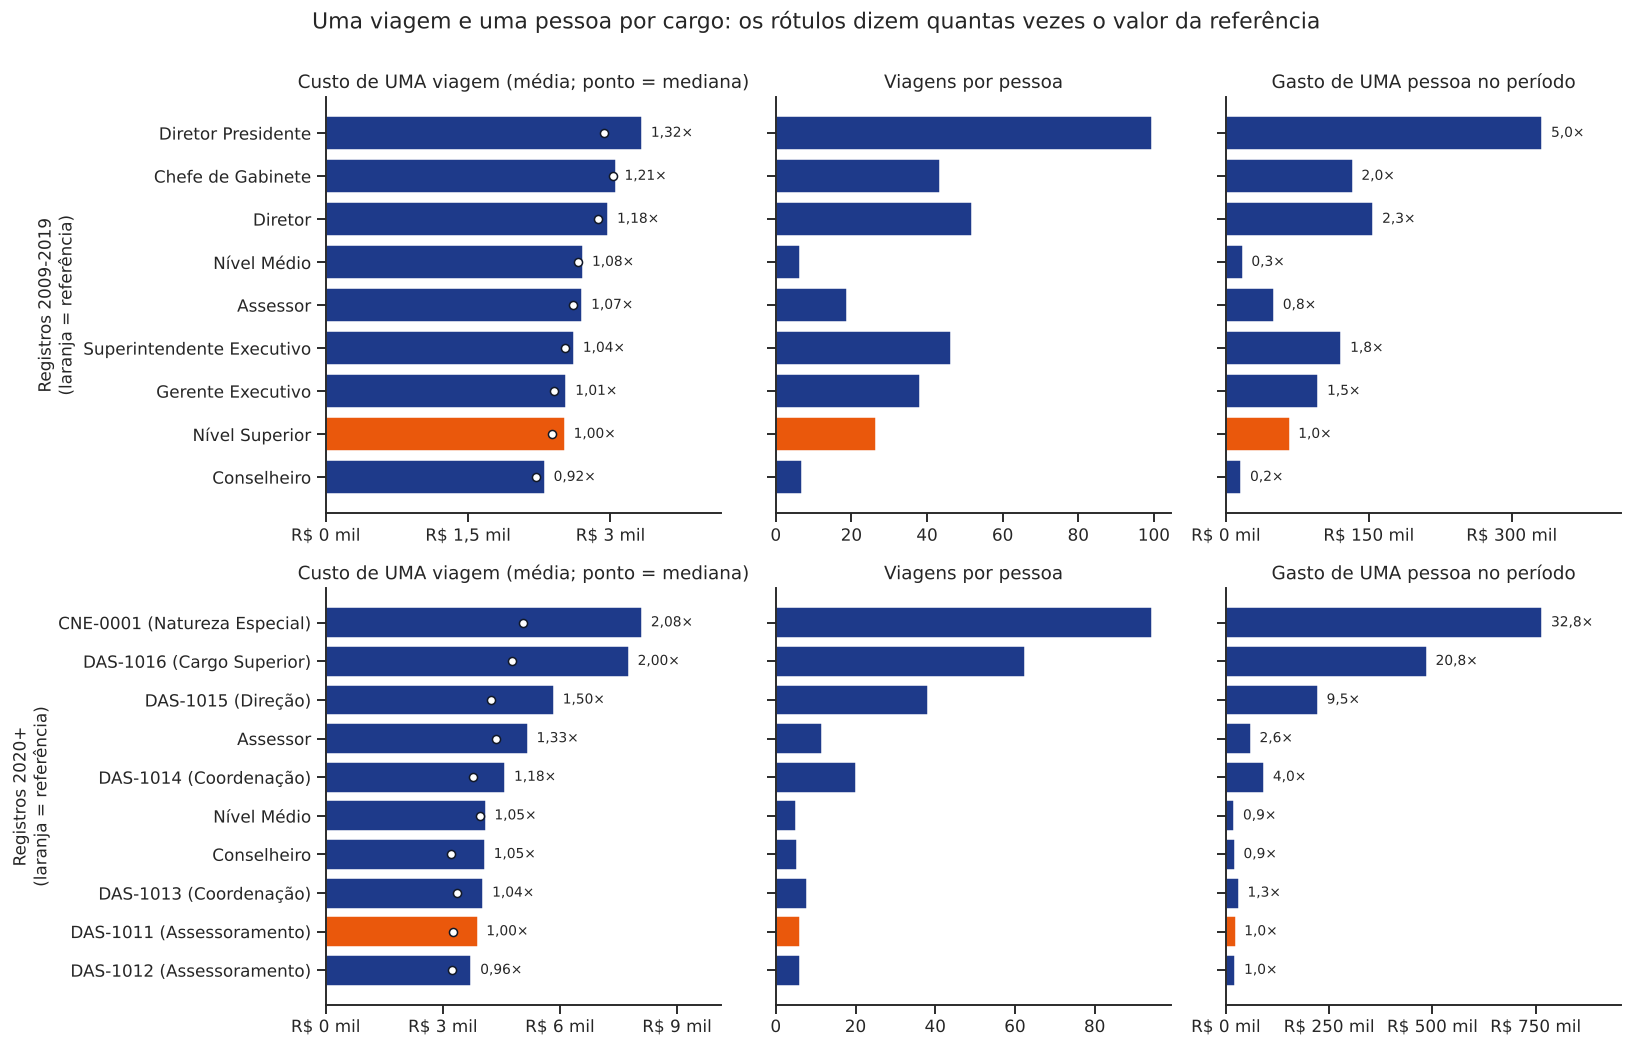

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for linha, formato in enumerate(["2009-2019", "2020+"]):
    c = tabelas_cargo[formato].sort_values("custo_medio_viagem")
    ref = REFERENCIA[formato]
    cores = [LARANJA if nome == ref else AZUL for nome in c.index]

    ax = axes[linha, 0]
    ax.barh(c.index, c["custo_medio_viagem"], color=cores)
    ax.scatter(c["custo_mediano_viagem"], c.index, color="white", edgecolor="#111827", s=28, zorder=3, label="mediana")
    for y, eq in enumerate(c["equivale_a_viagens_ref_media"]):
        ax.text(c["custo_medio_viagem"].iloc[y], y, f"  {eq:.2f}×".replace(".", ","), va="center", fontsize=9)
    ax.set_xlim(0, c["custo_medio_viagem"].max() * 1.25)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R$ {x/1e3:g} mil".replace(".", ",")))
    ax.set_title("Custo de UMA viagem (média; ponto = mediana)")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))

    ax = axes[linha, 1]
    ax.barh(c.index, c["viagens_por_pessoa"], color=cores)
    ax.set_yticklabels([])
    ax.set_title("Viagens por pessoa")

    ax = axes[linha, 2]
    ax.barh(c.index, c["gasto_por_pessoa"], color=cores)
    for y, r in enumerate(c["gasto_por_pessoa_vs_ref"]):
        ax.text(c["gasto_por_pessoa"].iloc[y], y, f"  {r:.1f}×".replace(".", ","), va="center", fontsize=9)
    ax.set_xlim(0, c["gasto_por_pessoa"].max() * 1.25)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R$ {x/1e3:g} mil".replace(".", ",")))
    ax.set_yticklabels([])
    ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
    ax.set_title("Gasto de UMA pessoa no período")

    axes[linha, 0].set_ylabel(f"Registros {formato}\n(laranja = referência)", fontsize=11)

fig.suptitle("Uma viagem e uma pessoa por cargo: os rótulos dizem quantas vezes o valor da referência", y=1.0)
fig.tight_layout()
salvar(fig, "fig_cargo_por_pessoa.png")
plt.show()

**Leitura:** até 2019, uma viagem de Diretor custava só 18% a mais que uma de Nível Superior (1,18 viagem de NS), mas cada diretor viajou duas vezes mais e, por isso, gastou 2,3 vezes mais por pessoa. A partir de 2020 a diferença por viagem cresce nos cargos do topo, em parte porque eles concentram as viagens internacionais; como a média é puxada por essas viagens caras, a mediana mostra uma diferença menor.

### 3.3 Por área (organograma, dirigentes atuais)

O organograma é a única base pública com a **lotação**, mas lista apenas os 34 dirigentes atuais (diretores e superintendentes). As viagens deles são 3,7% do total, então este recorte responde "quais áreas da liderança mais viajam", não o banco inteiro.

**Como o setor foi montado:** o portal não tem uma tabela de setores; o organograma traz só a sigla da lotação. Por isso o nome de cada área e a diretoria a que ela pertence foram **digitados à mão** no código (`AREAS` e `DIRETORIAS` em `src/etl.py`), a partir do Organograma Geral do BNDES e da página "Quem é quem" (atualização de 13/10/2026). O pipeline para com erro se aparecer uma sigla sem mapeamento.

As viagens de cada dirigente cobrem toda a série (2009–2026), inclusive o período antes do cargo atual.

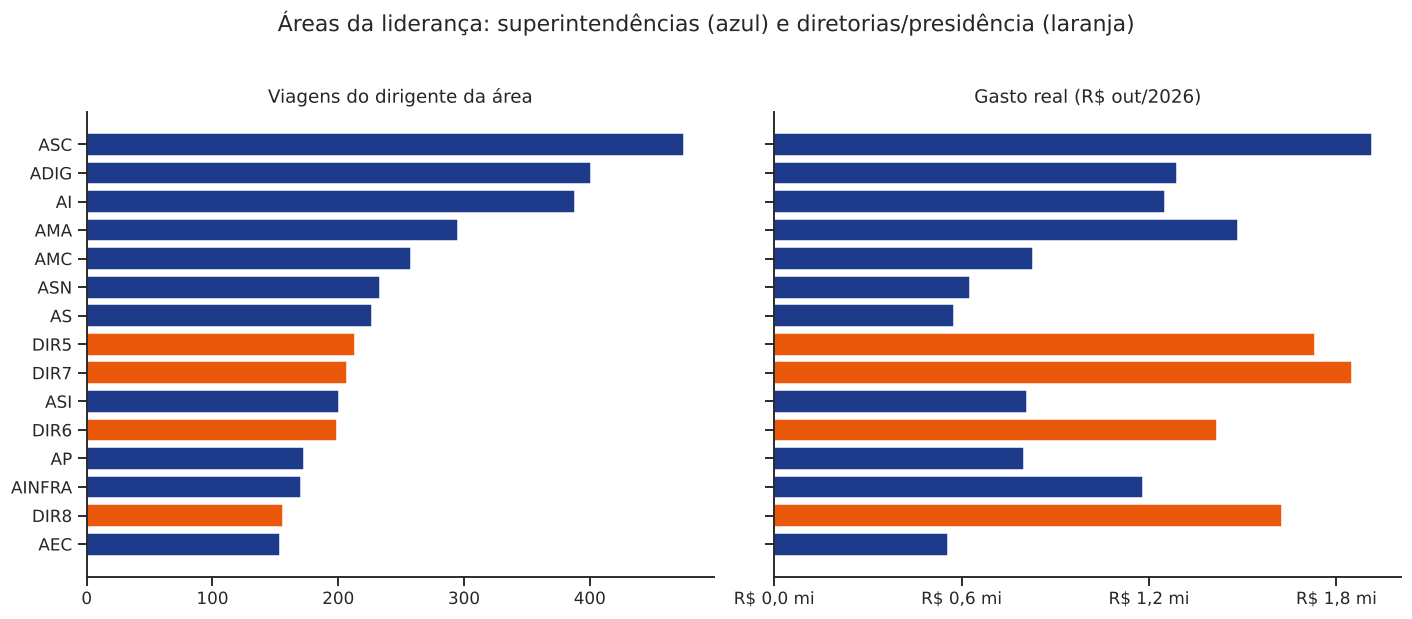

area_sigla  area_nome                                                   diretoria                                                     
ASC         Área de Soluções para Cidades                               DIR8 · Planejamento e Relações Institucionais                     475
ADIG        Área de Operações e Canais Digitais                         DIR4 · Crédito Digital para MPMEs e Gestão do Fundo Rio Doce      401
AI          Área de Desenvolvimento Produtivo e Inovação                DIR7 · Desenvolvimento Produtivo, Inovação e Comércio Exterior    388
AMA         Área de Meio Ambiente                                       DIR2 · Socioambiental                                             295
AMC         Área de Mercado de Capitais, Investimentos e Participações  DIR3 · Financeira e de Mercado de Capitais                        258
ASN         Área de Suporte ao Negócio                                  DIR1 · Pessoas, TI e Operações                                    233
AS          Á

In [17]:
area = df.dropna(subset=["area_sigla"]).groupby(["area_sigla", "funcao_dirigente"]).agg(
    viagens=("codigoviagem", "size"), gasto_real=("valor_total_real", "sum"), custo_mediano=("valor_total_real", "median")
).reset_index().sort_values("viagens", ascending=False)

top_area = area.head(15).iloc[::-1]
cores = [LARANJA if f != "Superintendente" else AZUL for f in top_area["funcao_dirigente"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
axes[0].barh(top_area["area_sigla"], top_area["viagens"], color=cores)
axes[0].set_title("Viagens do dirigente da área")
axes[1].barh(top_area["area_sigla"], top_area["gasto_real"], color=cores)
axes[1].set_title("Gasto real (R$ out/2026)")
axes[1].xaxis.set_major_locator(mticker.MaxNLocator(4))
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R$ {x/1e6:.1f} mi".replace(".", ",")))
fig.suptitle("Áreas da liderança: superintendências (azul) e diretorias/presidência (laranja)", y=1.02)
fig.tight_layout()
salvar(fig, "fig_area.png")
plt.show()
df.dropna(subset=["area_sigla"]).groupby(["area_sigla", "area_nome", "diretoria"]).size().rename("viagens").sort_values(ascending=False).head(10)

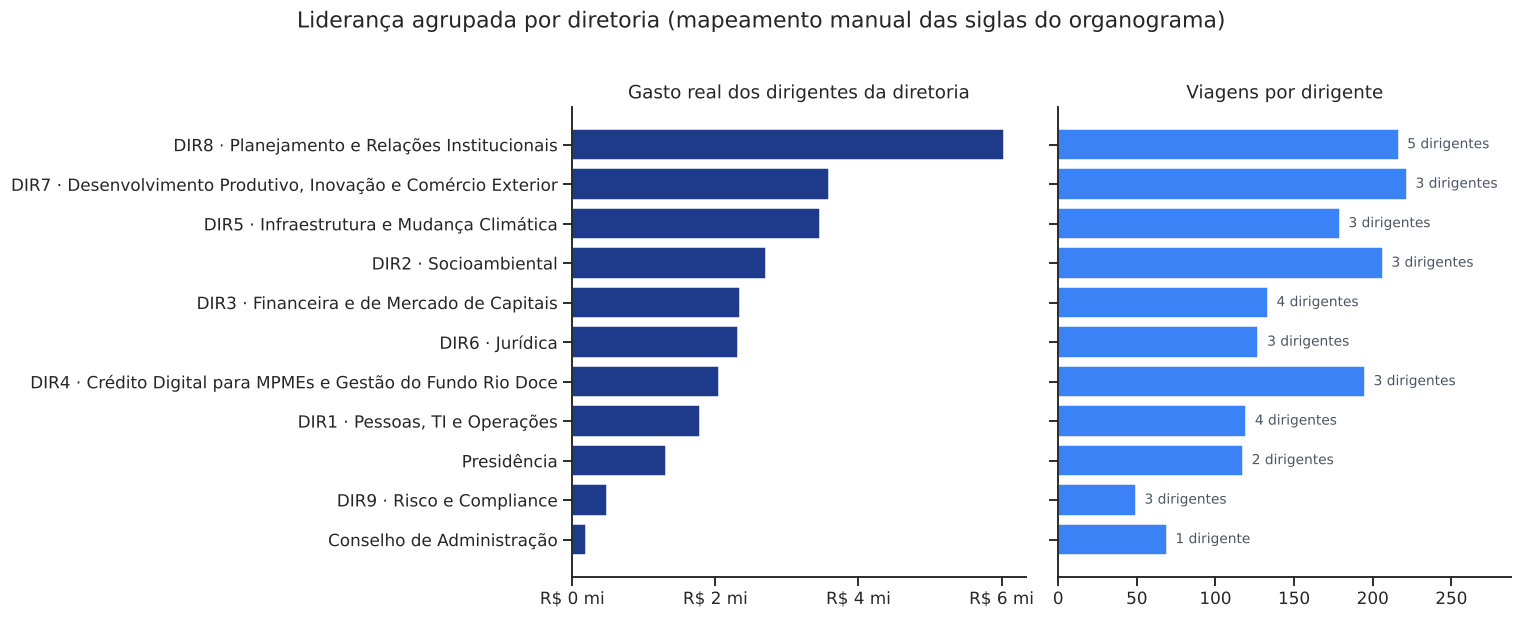

,viagens,dirigentes,gasto_real,custo_mediano,viagens_por_dirigente,gasto_por_dirigente
diretoria,,,,,,
DIR8 · Planejamento e Relações Institucionais,1082,5,"6,033,393.18","3,267.70",216.40,"1,206,678.64"
"DIR7 · Desenvolvimento Produtivo, Inovação e Comércio Exterior",665,3,"3,593,764.51","3,344.21",221.67,"1,197,921.50"
DIR5 · Infraestrutura e Mudança Climática,537,3,"3,465,479.92","4,031.24",179.00,"1,155,159.97"
DIR2 · Socioambiental,619,3,"2,710,792.95","3,172.93",206.33,"903,597.65"
DIR3 · Financeira e de Mercado de Capitais,533,4,"2,342,869.53","3,351.58",133.25,"585,717.38"
DIR6 · Jurídica,382,3,"2,315,682.40","4,291.20",127.33,"771,894.13"
DIR4 · Crédito Digital para MPMEs e Gestão do Fundo Rio Doce,585,3,"2,050,661.32","3,072.47",195.00,"683,553.77"
"DIR1 · Pessoas, TI e Operações",478,4,"1,782,772.61","2,807.24",119.50,"445,693.15"
Presidência,235,2,"1,311,035.01","3,693.00",117.50,"655,517.51"


In [18]:
dir_ = df.dropna(subset=["diretoria"]).groupby("diretoria").agg(
    viagens=("codigoviagem", "size"), dirigentes=("pessoa_id", "nunique"),
    gasto_real=("valor_total_real", "sum"), custo_mediano=("valor_total_real", "median"),
)
dir_["viagens_por_dirigente"] = dir_["viagens"] / dir_["dirigentes"]
dir_["gasto_por_dirigente"] = dir_["gasto_real"] / dir_["dirigentes"]
dir_ = dir_.sort_values("gasto_real")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
axes[0].barh(dir_.index, dir_["gasto_real"], color=AZUL)
axes[0].xaxis.set_major_locator(mticker.MaxNLocator(4))
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R$ {x/1e6:.0f} mi"))
axes[0].set_title("Gasto real dos dirigentes da diretoria")
axes[1].barh(dir_.index, dir_["viagens_por_dirigente"], color=AZUL_CLARO)
axes[1].set_title("Viagens por dirigente")
for y, n in enumerate(dir_["dirigentes"]):
    axes[1].text(dir_["viagens_por_dirigente"].iloc[y], y, f"  {n} dirigente{'s' if n > 1 else ''}", va="center", fontsize=9, color="#4b5563")
axes[1].set_xlim(0, dir_["viagens_por_dirigente"].max() * 1.3)
fig.suptitle("Liderança agrupada por diretoria (mapeamento manual das siglas do organograma)", y=1.02)
fig.tight_layout()
salvar(fig, "fig_diretoria.png")
plt.show()
dir_.sort_values("gasto_real", ascending=False)

### 3.4 Por motivo

A análise usa `motivo_principal`: o primeiro motivo quando o registro lista vários ("Fomento / Análise de projeto") e um rótulo único para atividades que mudaram de nome em 2020 ("Treinamento centralizado" até 2019 e "Treinamento no Brasil" depois viram "Treinamento nacional"). A tabela mostra por que a unificação é necessária:

In [19]:
trein = df[df["motivo"].str.contains("TREINAMENTO")]
pd.crosstab(trein["motivo"], trein["ano"]).loc[:, 2017:]

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
motivo,,,,,,,,,,
INTERNACIONAL TREINAMENTO GVIG,0,0,0,6,1,27,29,14,27,6
TREINAMENTO - PROJETOS ESPECIAIS,0,0,0,0,0,23,2,0,26,12
TREINAMENTO CENTRALIZADO,801,664,620,0,0,0,0,0,0,0
TREINAMENTO NO BRASIL,0,0,0,50,9,211,286,291,395,239


In [20]:
motivo = df.groupby("motivo_principal").agg(viagens=("codigoviagem", "size"), gasto_real=("valor_total_real", "sum"),
                                 custo_mediano=("valor_total_real", "median"))
motivo["pct_viagens"] = motivo["viagens"] / motivo["viagens"].sum() * 100
motivo = motivo.sort_values("viagens", ascending=False)
print(f"{len(motivo)} motivos principais; os 10 maiores somam {motivo['pct_viagens'].head(10).sum():.0f}% das viagens")
motivo.head(10)

94 motivos principais; os 10 maiores somam 90% das viagens


,viagens,gasto_real,custo_mediano,pct_viagens
motivo_principal,,,,
ACOMPANHAMENTO DE PROJETO,28915,"79,152,455.55","2,498.74",19.95
REUNIAO EM ORGAOS GOVERNAMENTAIS,25963,"80,913,297.15","2,807.00",17.91
"PARTICIPACAO EM CONGRESSOS, FEIRAS E SEMINARIOS",17238,"46,496,459.71","2,505.74",11.89
FOMENTO,12241,"32,292,042.02","2,353.85",8.45
TREINAMENTO NACIONAL,10281,"27,028,917.69","2,477.87",7.09
ANALISE DE PROJETO,9152,"24,467,169.70","2,440.76",6.31
OUTROS,8900,"23,859,536.78","2,508.69",6.14
REUNIAO NOS ESCRITORIOS REGIONAIS,8217,"26,808,944.98","2,892.67",5.67
REPRESENTACAO EM COLEGIADOS,5313,"12,772,425.72","2,209.74",3.67


## 4. RQ3: o efeito da pandemia

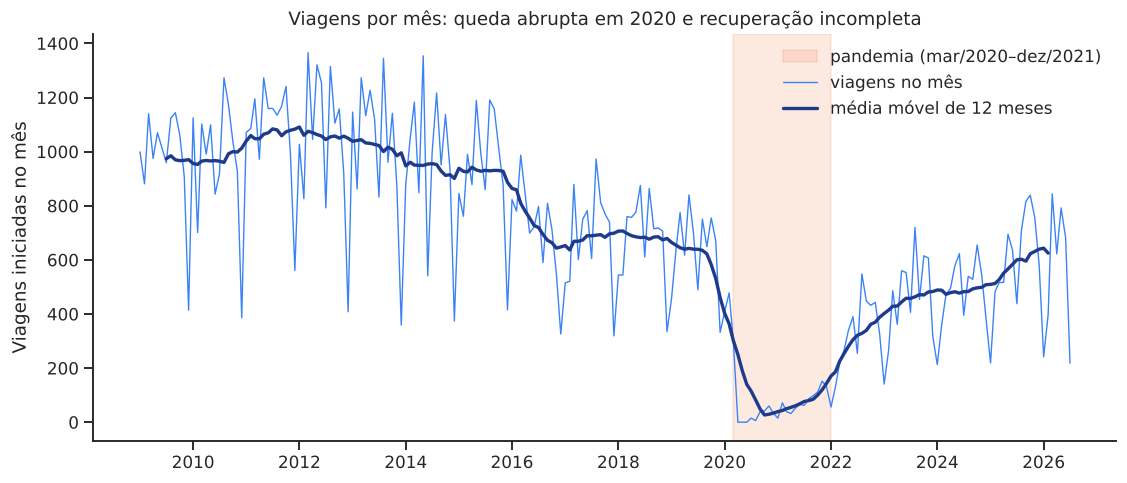

meses sem nenhuma viagem: ['04/2020', '05/2020', '06/2020']


In [21]:
mensal = df.groupby("mes").size().reindex(pd.date_range(df["mes"].min(), df["mes"].max(), freq="MS"), fill_value=0)
media_movel = mensal.rolling(12, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.axvspan(etl.INICIO_PANDEMIA, etl.FIM_PANDEMIA, color=LARANJA, alpha=0.12, label="pandemia (mar/2020–dez/2021)")
ax.plot(mensal.index, mensal.values, color=AZUL_CLARO, lw=0.9, label="viagens no mês")
ax.plot(media_movel.index, media_movel.values, color=AZUL, lw=2.2, label="média móvel de 12 meses")
ax.set_title("Viagens por mês: queda abrupta em 2020 e recuperação incompleta")
ax.set_ylabel("Viagens iniciadas no mês")
ax.legend(frameon=False, loc="upper right")
salvar(fig, "fig_serie_mensal.png")
plt.show()

meses_zerados = mensal[mensal == 0]
print("meses sem nenhuma viagem:", [f"{m:%m/%Y}" for m in meses_zerados.index])

In [22]:
anual = df.groupby("ano").agg(viagens=("codigoviagem", "size"), pessoas=("pessoa_id", "nunique"),
                              gasto_real=("valor_total_real", "sum"), custo_mediano_real=("valor_total_real", "median"),
                              diarias_medianas=("n_diarias", "median"), internacionais=("internacional", "mean"))
anual["var_viagens_vs_2019"] = (anual["viagens"] / anual.loc[2019, "viagens"] - 1) * 100
anual

,viagens,pessoas,gasto_real,custo_mediano_real,diarias_medianas,internacionais,var_viagens_vs_2019
ano,,,,,,,
2009,11691,1787,"33,914,850.98","2,749.58",2.00,0.00,52.41
2010,11576,1820,"30,141,166.10","2,512.82",2.00,0.00,50.91
2011,13008,2061,"34,694,915.00","2,601.73",2.00,0.00,69.57
2012,12537,1970,"31,746,217.53","2,387.64",2.00,0.00,63.43
2013,12270,1951,"33,988,885.88","2,689.36",2.00,0.00,59.95
2014,11465,1954,"30,043,350.91","2,512.51",2.00,0.00,49.46
2015,11171,1901,"26,562,364.00","2,233.58",2.00,0.00,45.63
2016,8636,1791,"18,364,667.35","1,993.56",2.00,0.00,12.58
2017,8266,1686,"17,241,647.48","1,899.61",2.00,0.00,7.76


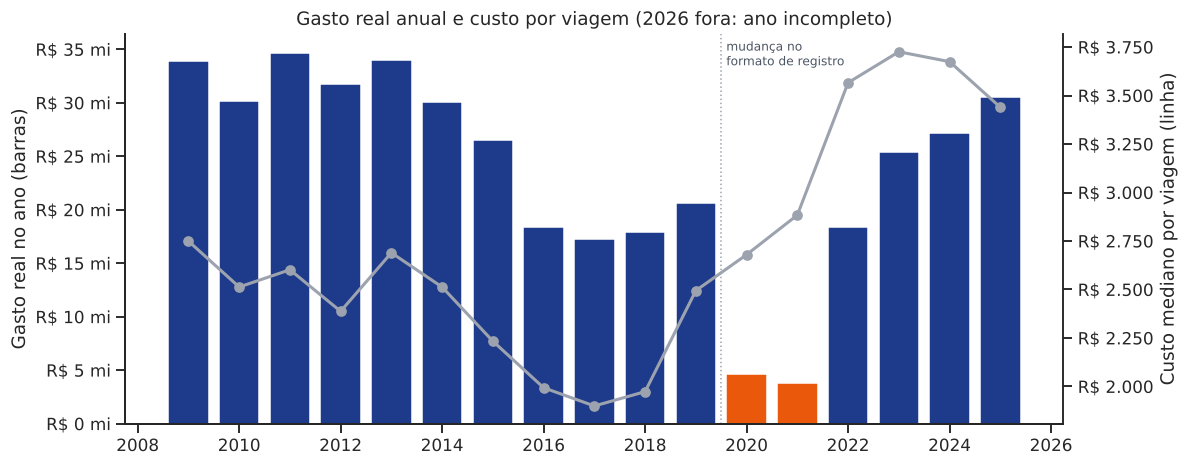

In [23]:
fig, ax1 = plt.subplots(figsize=(11, 4.6))
anos_completos = anual.loc[:2025]
ax1.bar(anos_completos.index, anos_completos["gasto_real"], color=[LARANJA if a in (2020, 2021) else AZUL for a in anos_completos.index])
ax1.yaxis.set_major_formatter(reais)
ax1.set_ylabel("Gasto real no ano (barras)")
ax2 = ax1.twinx()
ax2.plot(anos_completos.index, anos_completos["custo_mediano_real"], color=CINZA, marker="o", lw=2)
ax2.set_ylabel("Custo mediano por viagem (linha)")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"R$ {x:,.0f}".replace(",", ".")))
ax2.spines["right"].set_visible(True)
ax1.axvline(2019.5, color=CINZA, ls=":", lw=1)
ax1.text(2019.6, ax1.get_ylim()[1] * 0.92, "mudança no\nformato de registro", fontsize=8, color="#4b5563")
ax1.set_title("Gasto real anual e custo por viagem (2026 fora: ano incompleto)")
ax1.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax1.xaxis.set_major_formatter(mticker.FormatStrFormatter("%d"))
salvar(fig, "fig_gasto_anual.png")
plt.show()

In [24]:
base = df[df["ano"].isin([2019, 2020, 2021, 2023])].copy()
base["janela"] = base["ano"].map({2019: "2019", 2020: "2020–21 (média anual)", 2021: "2020–21 (média anual)", 2023: "2023"})
tab = pd.crosstab(base["motivo_principal"], base["janela"])
tab["2020–21 (média anual)"] = tab["2020–21 (média anual)"] / 2
tab = tab.loc[tab["2019"].sort_values(ascending=False).index[:10]]
tab["queda_pandemia_%"] = (tab["2020–21 (média anual)"] / tab["2019"] - 1) * 100
tab["2023_vs_2019_%"] = (tab["2023"] / tab["2019"] - 1) * 100
tab.round(0)

janela,2019,2020–21 (média anual),2023,queda_pandemia_%,2023_vs_2019_%
motivo_principal,,,,,
REUNIAO EM ORGAOS GOVERNAMENTAIS,1785,430.00,1234,-76.00,-31.00
ACOMPANHAMENTO DE PROJETO,1124,190.00,631,-83.00,-44.00
FOMENTO,994,80.00,408,-92.00,-59.00
"PARTICIPACAO EM CONGRESSOS, FEIRAS E SEMINARIOS",817,28.00,751,-97.00,-8.00
TREINAMENTO NACIONAL,620,30.00,286,-95.00,-54.00
OUTROS,424,58.00,55,-86.00,-87.00
REPRESENTACAO EM COLEGIADOS,418,30.00,127,-93.00,-70.00
ANALISE DE PROJETO,388,44.00,252,-89.00,-35.00
REUNIAO NOS ESCRITORIOS REGIONAIS,372,146.00,737,-61.00,98.00


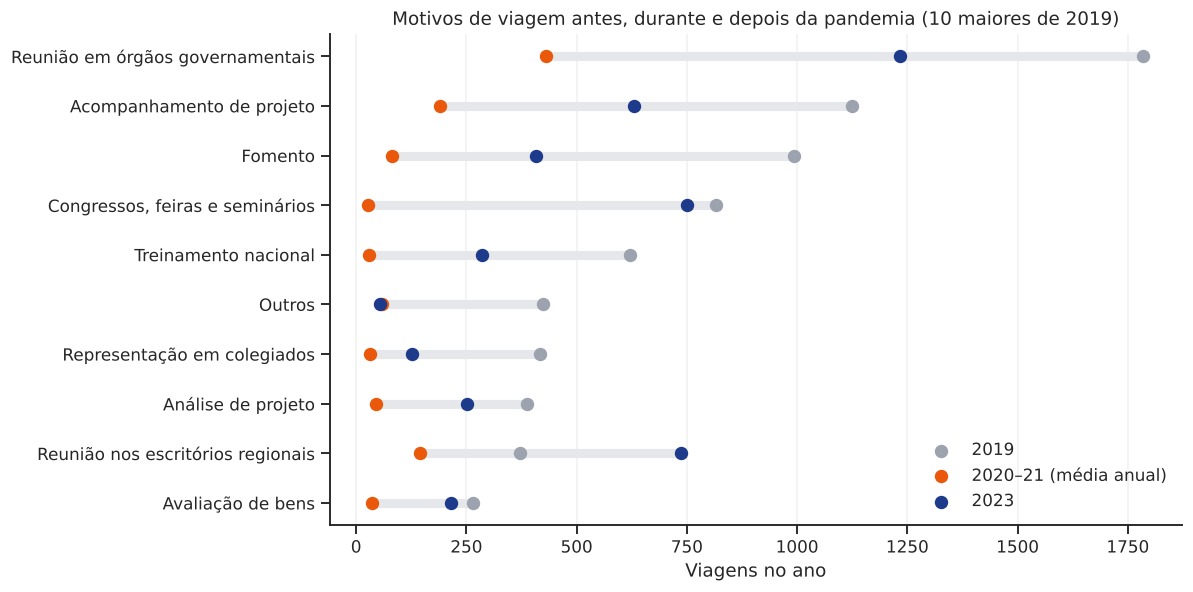

In [25]:
plot = tab[["2019", "2020–21 (média anual)", "2023"]].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.8))
y = np.arange(len(plot))
ax.hlines(y, plot.min(axis=1), plot.max(axis=1), color="#e5e7eb", lw=6)
ax.scatter(plot["2019"], y, color=CINZA, s=60, label="2019", zorder=3)
ax.scatter(plot["2020–21 (média anual)"], y, color=LARANJA, s=60, label="2020–21 (média anual)", zorder=3)
ax.scatter(plot["2023"], y, color=AZUL, s=60, label="2023", zorder=3)
ax.set_yticks(y, [rotulo_motivo(m) for m in plot.index])
ax.set_xlabel("Viagens no ano")
ax.set_title("Motivos de viagem antes, durante e depois da pandemia (10 maiores de 2019)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="x", alpha=0.3)
salvar(fig, "fig_motivos_pandemia.png")
plt.show()

## 5. Síntese

Os números citados no artigo saem das tabelas acima. Resumo final para conferência:

In [26]:
r = {
    "viagens": len(df),
    "pessoas": df["pessoa_id"].nunique(),
    "gasto_real_total_mi": df["valor_total_real"].sum() / 1e6,
    "profissao_mais_viagens": prof.index[0],
    "profissao_mais_gasto": prof["gasto_real"].idxmax(),
    "profissao_mais_viagens_por_pessoa_20+": prof[prof["pessoas"] >= 20]["viagens_por_pessoa"].idxmax(),
    "area_mais_viagens": area.iloc[0]["area_sigla"],
    "area_mais_gasto": area.sort_values("gasto_real").iloc[-1]["area_sigla"],
    "queda_2020_%": anual.loc[2020, "var_viagens_vs_2019"],
    "queda_2021_%": anual.loc[2021, "var_viagens_vs_2019"],
    "2025_vs_2019_%": anual.loc[2025, "var_viagens_vs_2019"],
    "gini_gasto": gini,
    "top10_pct_gasto": top10 * 100,
}
pd.Series(r)

viagens                                      144930
pessoas                                        5480
gasto_real_total_mi                          421.16
profissao_mais_viagens                   Engenheiro
profissao_mais_gasto                     Engenheiro
profissao_mais_viagens_por_pessoa_20+    Engenheiro
area_mais_viagens                               ASC
area_mais_gasto                                 ASC
queda_2020_%                                 -82.00
queda_2021_%                                 -88.03
2025_vs_2019_%                                -6.09
gini_gasto                                     0.75
top10_pct_gasto                               57.36
dtype: object